Best on train: short=50, long=180
  Train return: +400%  |  Test return: +453%
Buy & hold:     Train +196%  |  Test +925%

Hindsight best on test: short=20, long=140 -> +1018%
Train-best ranked #125 of 174 on the test period
Train vs test rank correlation: -0.02


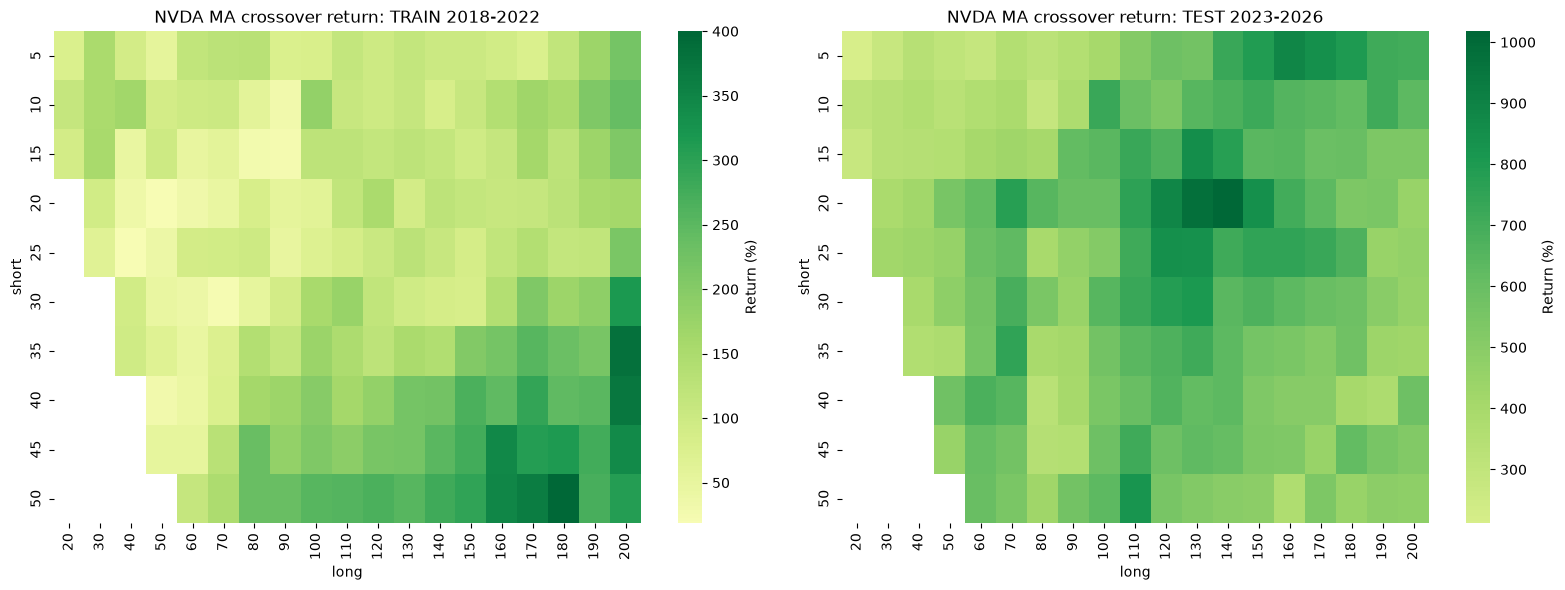

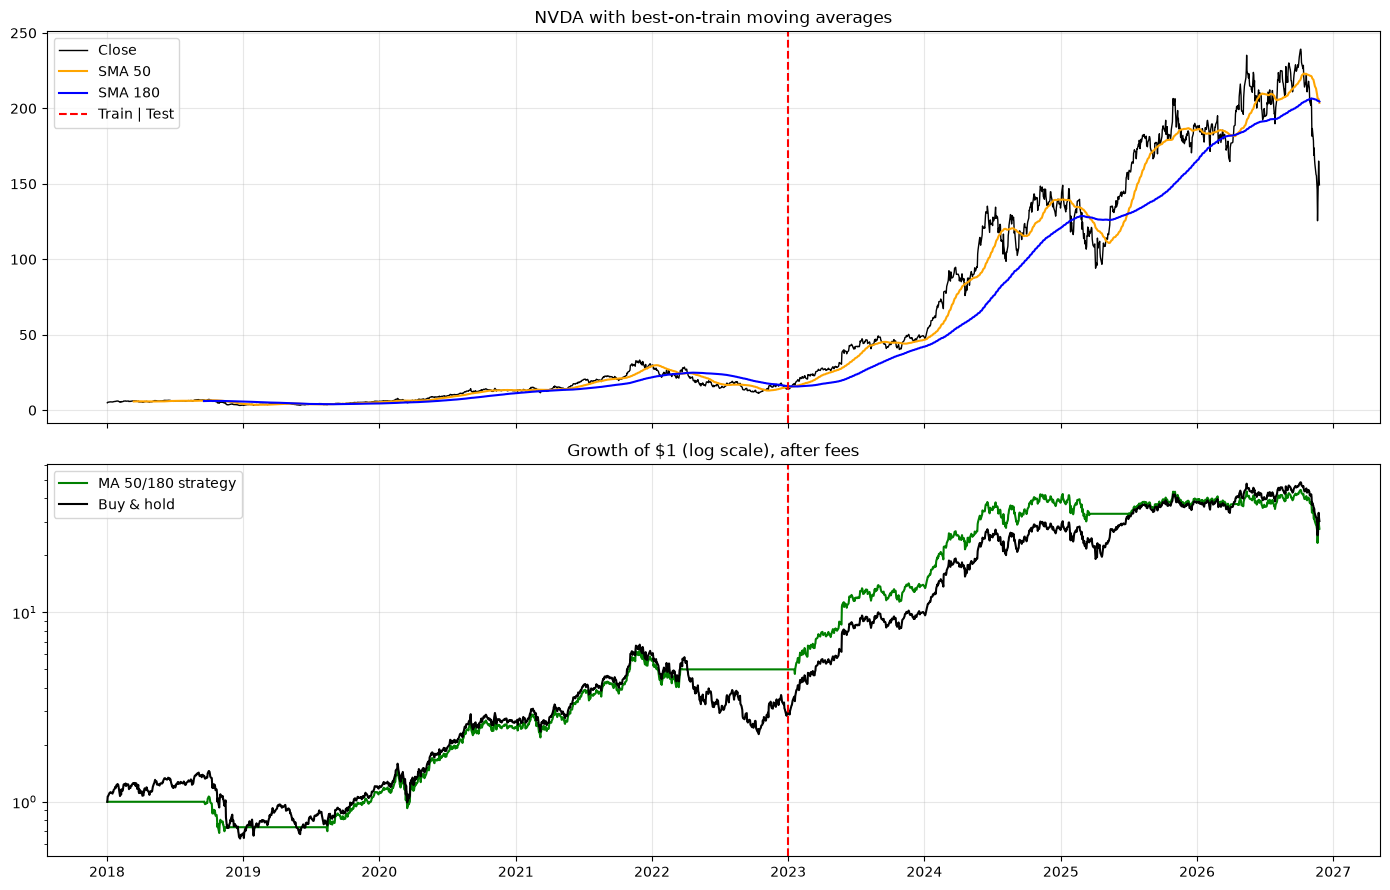

In [8]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ticker = "NVDA"
fee = 0.001                      # 0.1% per trade
split = pd.Timestamp("2023-01-01")

# Get data
df = yf.download(ticker, start="2018-01-01", multi_level_index=False, progress=False)[["Close"]].dropna()
close = df["Close"]

# Moving average crossover strategy
def ma_crossover(close, short, long, fee=fee):
    s = close.rolling(short).mean()
    l = close.rolling(long).mean()
    pos = (s > l).astype(float).shift(1).fillna(0)   # act the NEXT day (no peeking)
    ret = close.pct_change().fillna(0)
    trades = pos.diff().abs().fillna(0)
    return pos * ret - trades * fee                  # daily strategy returns

def total(r):
    return (1 + r).prod() - 1

# Grid search: best on TRAIN only
rows = []
for sw in range(5, 55, 5):
    for lw in range(20, 210, 10):
        if sw >= lw:
            continue
        r = ma_crossover(close, sw, lw)
        rows.append({"short": sw, "long": lw,
                     "train": total(r[r.index < split]),
                     "test": total(r[r.index >= split])})
grid = pd.DataFrame(rows)

best = grid.loc[grid["train"].idxmax()]
hindsight = grid.loc[grid["test"].idxmax()]
bh = close.pct_change().fillna(0)

print(f"Best on train: short={best.short:.0f}, long={best.long:.0f}")
print(f"  Train return: {best.train:+.0%}  |  Test return: {best.test:+.0%}")
print(f"Buy & hold:     Train {total(bh[bh.index < split]):+.0%}  |  Test {total(bh[bh.index >= split]):+.0%}")
print(f"\nHindsight best on test: short={hindsight.short:.0f}, long={hindsight.long:.0f} -> {hindsight.test:+.0%}")
rank = (grid["test"] > best.test).sum() + 1
print(f"Train-best ranked #{rank} of {len(grid)} on the test period")
print(f"Train vs test rank correlation: {grid[['train', 'test']].corr(method='spearman').iloc[0, 1]:.2f}")

# Plot 1: heatmaps (train vs test)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in [(axes[0], "train", "TRAIN 2018-2022"), (axes[1], "test", "TEST 2023-2026")]:
    pv = grid.pivot(index="short", columns="long", values=col) * 100
    sns.heatmap(pv, cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "Return (%)"})
    ax.set_title(f"{ticker} MA crossover return: {title}")
plt.tight_layout()
plt.show()

# Plot 2: price + best MAs, and equity vs buy & hold
sw, lw = int(best.short), int(best.long)
r_best = ma_crossover(close, sw, lw)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
ax1.plot(close, label="Close", color="black", linewidth=1)
ax1.plot(close.rolling(sw).mean(), label=f"SMA {sw}", color="orange")
ax1.plot(close.rolling(lw).mean(), label=f"SMA {lw}", color="blue")
ax1.axvline(split, color="red", linestyle="--", label="Train | Test")
ax1.set_title(f"{ticker} with best-on-train moving averages")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot((1 + r_best).cumprod(), label=f"MA {sw}/{lw} strategy", color="green")
ax2.plot((1 + bh).cumprod(), label="Buy & hold", color="black")
ax2.axvline(split, color="red", linestyle="--")
ax2.set_yscale("log")
ax2.set_title("Growth of $1 (log scale), after fees")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Version                                 Final   Return   Max DD
His original (buggy, long/short)   $    8,300     -17%     -47%
Fixed, long/short                  $    6,272     -37%     -52%
Fixed, long/cash                   $   12,610     +26%     -29%
Buy & hold                         $   23,232    +132%     -33%


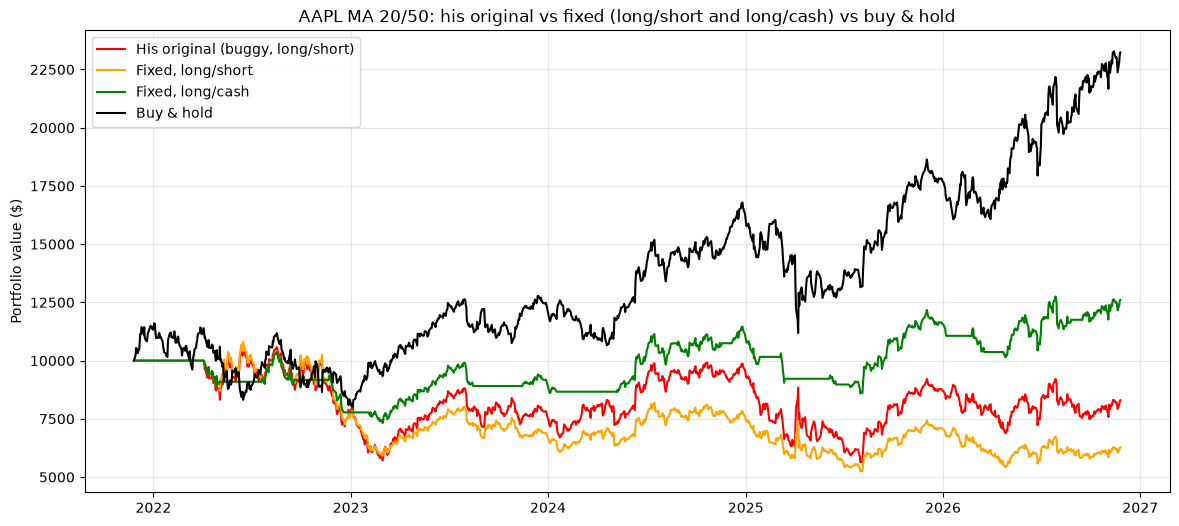

In [11]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def calculate_and_backtest(data, short_window, long_window, initial_capital=10000,
                           fee=0.001, allow_short=True):
    data = data.copy()
    data["Short_MA"] = data["Close"].rolling(window=short_window).mean()
    data["Long_MA"] = data["Close"].rolling(window=long_window).mean()

    # Generate Buy and Sell Signals
    data["Buy_Signal"] = (data["Short_MA"] > data["Long_MA"]) & (data["Short_MA"].shift(1) <= data["Long_MA"].shift(1))
    data["Sell_Signal"] = (data["Short_MA"] < data["Long_MA"]) & (data["Short_MA"].shift(1) >= data["Long_MA"].shift(1))

    # Create Position Column (1 = long, -1 = short, 0 = cash)
    data["Position"] = np.nan
    data.loc[data["Buy_Signal"], "Position"] = 1
    data.loc[data["Sell_Signal"], "Position"] = -1 if allow_short else 0
    data["Position"] = data["Position"].ffill().fillna(0)

    # Daily returns: act the NEXT day, pay fees on position changes
    data["Daily_Return"] = data["Close"].pct_change()
    trades = data["Position"].diff().abs().fillna(0)
    data["Strategy_Return"] = data["Daily_Return"] * data["Position"].shift(1) - trades * fee

    # Portfolio value with compounding
    data["Portfolio_Value"] = initial_capital * (1 + data["Strategy_Return"].fillna(0)).cumprod()
    return data

def max_drawdown(values):
    return (values / values.cummax() - 1).min()

# ===== Run all versions on his setup: AAPL, 5 years, MA 20/50 =====
data = yf.download("AAPL", period="5y", interval="1d", multi_level_index=False, progress=False)
long_short = calculate_and_backtest(data, 20, 50, allow_short=True)
long_cash = calculate_and_backtest(data, 20, 50, allow_short=False)

# His original math (same-day returns, cumsum, no fees), long/short
orig = long_short.copy()
orig["Strategy_Return"] = orig["Daily_Return"] * orig["Position"]
orig["Portfolio_Value"] = 10000 * (1 + orig["Strategy_Return"].cumsum())

bh = 10000 * data["Close"] / data["Close"].iloc[0]

versions = {
    "His original (buggy, long/short)": orig["Portfolio_Value"],
    "Fixed, long/short": long_short["Portfolio_Value"],
    "Fixed, long/cash": long_cash["Portfolio_Value"],
    "Buy & hold": bh,
}
print(f"{'Version':34} {'Final':>10} {'Return':>8} {'Max DD':>8}")
for name, v in versions.items():
    print(f"{name:34} ${v.iloc[-1]:>9,.0f} {v.iloc[-1] / 10000 - 1:>+8.0%} {max_drawdown(v):>8.0%}")

plt.figure(figsize=(14, 6))
colors = ["red", "orange", "green", "black"]
for (name, v), c in zip(versions.items(), colors):
    plt.plot(v, label=name, color=c)
plt.title("AAPL MA 20/50: his original vs fixed (long/short and long/cash) vs buy & hold")
plt.ylabel("Portfolio value ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

His original:  $8,300
Fixed version: $6,272
Buy & hold:    $23,232


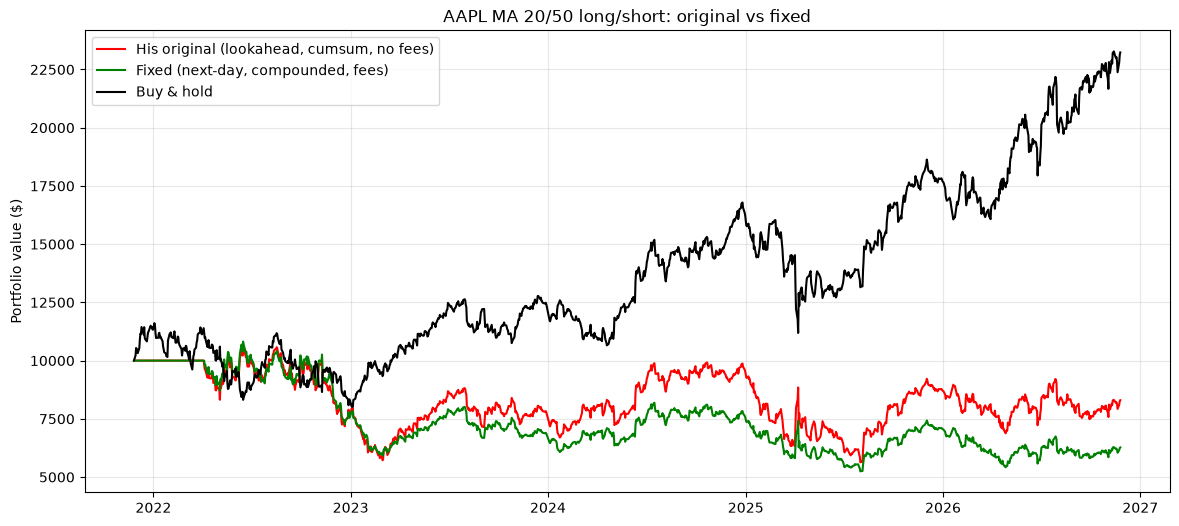

In [12]:
data = yf.download("AAPL", period="5y", interval="1d", multi_level_index=False, progress=False)
fixed = calculate_and_backtest(data, 20, 50)

# His original math, for comparison (same-day returns, cumsum, no fees)
orig = fixed.copy()
orig["Strategy_Return"] = orig["Daily_Return"] * orig["Position"]
orig["Portfolio_Value"] = 10000 * (1 + orig["Strategy_Return"].cumsum())

bh = 10000 * data["Close"].iloc[-1] / data["Close"].iloc[0]
print(f"His original:  ${orig['Portfolio_Value'].iloc[-1]:,.0f}")
print(f"Fixed version: ${fixed['Portfolio_Value'].iloc[-1]:,.0f}")
print(f"Buy & hold:    ${bh:,.0f}")

plt.figure(figsize=(14, 6))
plt.plot(orig["Portfolio_Value"], label="His original (lookahead, cumsum, no fees)", color="red")
plt.plot(fixed["Portfolio_Value"], label="Fixed (next-day, compounded, fees)", color="green")
plt.plot(10000 * data["Close"] / data["Close"].iloc[0], label="Buy & hold", color="black")
plt.title("AAPL MA 20/50 long/short: original vs fixed")
plt.ylabel("Portfolio value ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# ===== His grid search (fixed function, his ranges) =====
short_window_range = range(5, 31, 5)     # 5 to 30, step 5
long_window_range = range(40, 101, 10)   # 40 to 100, step 10

def total_return(r):
    return (1 + r.fillna(0)).prod() - 1

split = data.index[int(len(data) * 0.7)]   # first 70% = train, last 30% = test
rows = []
for short_window in short_window_range:
    for long_window in long_window_range:
        if short_window >= long_window:
            continue
        for mode, allow_short in [("long/short", True), ("long/cash", False)]:
            res = calculate_and_backtest(data, short_window, long_window, allow_short=allow_short)
            r = res["Strategy_Return"]
            rows.append({"mode": mode, "short": short_window, "long": long_window,
                         "full": total_return(r),
                         "train": total_return(r[r.index < split]),
                         "test": total_return(r[r.index >= split])})
grid = pd.DataFrame(rows)

bh_r = data["Close"].pct_change()
print(f"Buy & hold: full {total_return(bh_r):+.0%} | train {total_return(bh_r[bh_r.index < split]):+.0%} "
      f"| test {total_return(bh_r[bh_r.index >= split]):+.0%}\n")

for mode, g in grid.groupby("mode"):
    his_best = g.loc[g["full"].idxmax()]     # his method: best on ALL data
    honest = g.loc[g["train"].idxmax()]      # honest: best on train only
    rank = (g["test"] > honest["test"]).sum() + 1
    corr = g[["train", "test"]].corr(method="spearman").iloc[0, 1]
    print(f"--- {mode} ---")
    print(f"His method (best on all 5 yrs): {his_best.short:.0f}/{his_best.long:.0f} -> {his_best.full:+.0%}")
    print(f"Honest (best on train):         {honest.short:.0f}/{honest.long:.0f} -> train {honest.train:+.0%}, "
          f"test {honest.test:+.0%} (ranked #{rank} of {len(g)} on test)")
    print(f"Train vs test rank correlation: {corr:.2f}\n")

Buy & hold: full +132% | train +30% | test +78%

--- long/cash ---
His method (best on all 5 yrs): 5/90 -> +105%
Honest (best on train):         5/90 -> train +37%, test +50% (ranked #22 of 42 on test)
Train vs test rank correlation: -0.05

--- long/short ---
His method (best on all 5 yrs): 5/90 -> +58%
Honest (best on train):         5/90 -> train +28%, test +24% (ranked #21 of 42 on test)
Train vs test rank correlation: -0.02



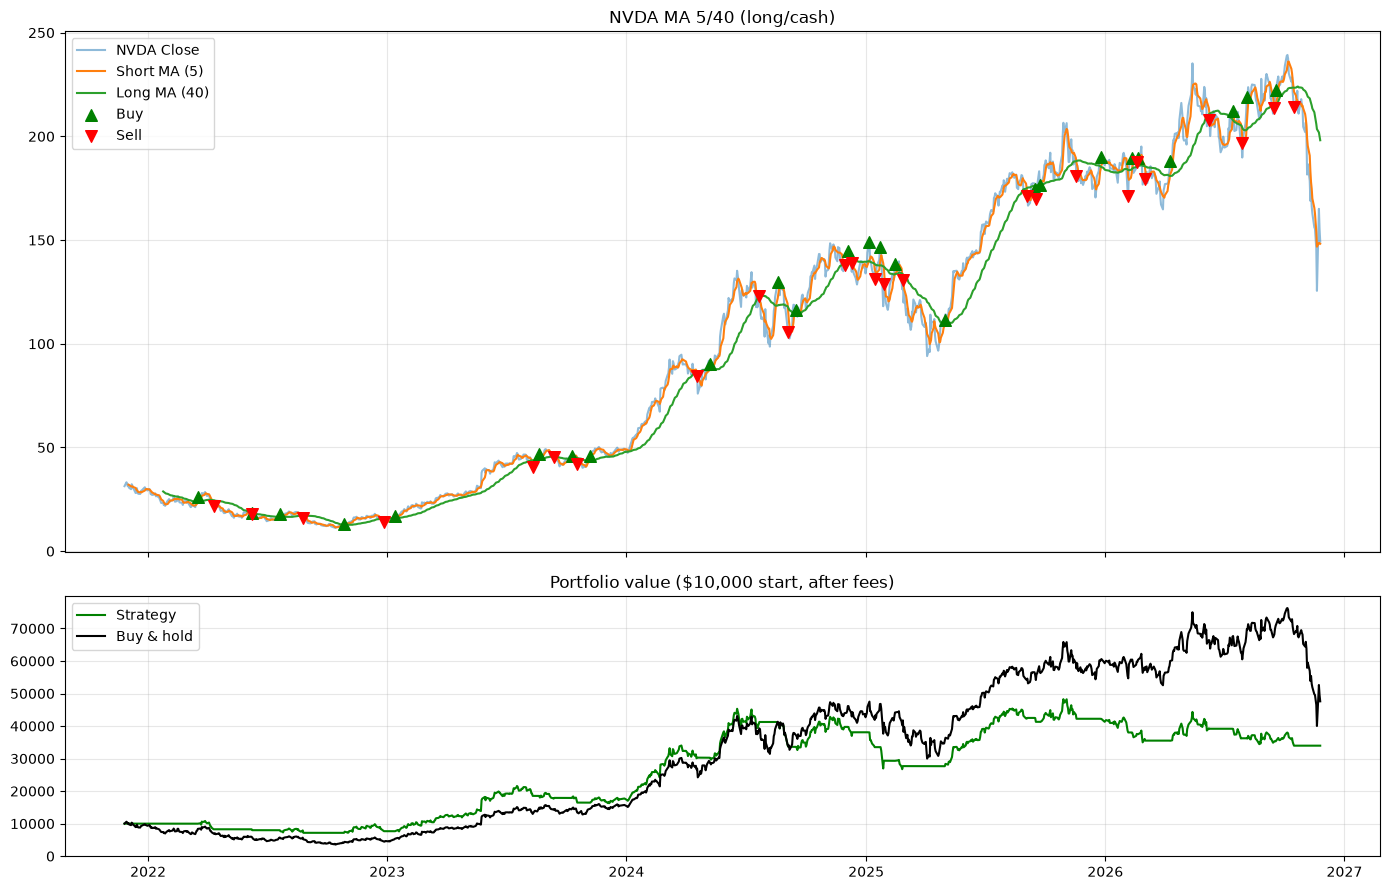

NVDA MA 5/40 long/cash: 50 signals (~10/yr)
Strategy $33,970 (max DD -41%) vs B&H $47,601 (max DD -66%)


In [15]:
ticker = "NVDA"
sw, lw = 5, 40
allow_short = False   # long/cash (your version); set True for stop-and-reverse

d = yf.download(ticker, period="5y", interval="1d", multi_level_index=False, progress=False)
res = calculate_and_backtest(d, sw, lw, allow_short=allow_short)
buys = res[res["Buy_Signal"]]
sells = res[res["Sell_Signal"]]
bh_t = 10000 * d["Close"] / d["Close"].iloc[0]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(res["Close"], label=f"{ticker} Close", alpha=0.5)
ax1.plot(res["Short_MA"], label=f"Short MA ({sw})")
ax1.plot(res["Long_MA"], label=f"Long MA ({lw})")
ax1.scatter(buys.index, buys["Close"], marker="^", color="green", s=70, label="Buy", zorder=3)
ax1.scatter(sells.index, sells["Close"], marker="v", color="red", s=70, label="Sell", zorder=3)
mode = "stop-and-reverse" if allow_short else "long/cash"
ax1.set_title(f"{ticker} MA {sw}/{lw} ({mode})")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(res["Portfolio_Value"], label="Strategy", color="green")
ax2.plot(bh_t, label="Buy & hold", color="black")
ax2.set_title("Portfolio value ($10,000 start, after fees)")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

flips = len(buys) + len(sells)
print(f"{ticker} MA {sw}/{lw} {mode}: {flips} signals (~{flips / 5:.0f}/yr)")
print(f"Strategy ${res['Portfolio_Value'].iloc[-1]:,.0f} (max DD {max_drawdown(res['Portfolio_Value']):.0%}) "
      f"vs B&H ${bh_t.iloc[-1]:,.0f} (max DD {max_drawdown(bh_t):.0%})")

In [16]:
tickers = ["NVDA", "MRVL", "XLE", "QQQ", "AAPL"]
print(f"{'Ticker':6} {'Best(train)':>11} {'Test':>7} {'B&H test':>9} {'Rank':>7} {'Corr':>6}")

for t in tickers:
    d = yf.download(t, period="5y", interval="1d", multi_level_index=False, progress=False)
    split_t = d.index[int(len(d) * 0.7)]
    rows = []
    for s in range(5, 31, 5):
        for l in range(40, 101, 10):
            r = calculate_and_backtest(d, s, l, allow_short=False)["Strategy_Return"]
            rows.append({"s": s, "l": l,
                         "train": total_return(r[r.index < split_t]),
                         "test": total_return(r[r.index >= split_t])})
    g = pd.DataFrame(rows)
    best = g.loc[g["train"].idxmax()]
    rank = (g["test"] > best["test"]).sum() + 1
    corr = g[["train", "test"]].corr(method="spearman").iloc[0, 1]
    bh_r = d["Close"].pct_change()
    print(f"{t:6} {best.s:>5.0f}/{best.l:<5.0f} {best.test:>+7.0%} {total_return(bh_r[bh_r.index >= split_t]):>+9.0%} "
          f"{rank:>3}/{len(g):<3} {corr:>6.2f}")

Ticker Best(train)    Test  B&H test    Rank   Corr
NVDA      30/100       -4%      +11%  32/42   -0.45
MRVL      30/50       +25%     +103%  25/42    0.19
XLE       30/100      +24%      +56%  32/42    0.33
QQQ        5/50       +18%      +23%  21/42    0.25
AAPL       5/90       +50%      +78%  22/42   -0.05


- 5-ticker grid (NVDA, MRVL, XLE, QQQ, AAPL; long/cash, 70/30): train-best lost to B&H on test 5/5; ranks 21-32/42; rank corr -0.45 to +0.33 (avg ~0)
- NVDA MA 5/40 long/cash: $33,970 vs B&H $47,601, but max DD -41% vs -66%; sat out the Nov 2026 crash. Crossover = risk control, not alpha

## Findings: MA crossover strategies (Nov 25)
- NVDA grid search (train 2018-22, test 2023-26): train-best 50/180 ranked #125/174 on test, rank corr -0.02 -> parameter choice doesn't carry over
- Real value of crossovers = drawdown avoidance (sat out 2022), not beating B&H on a trending stock
- His AAPL MA 20/50 long/short: bugs (same-day returns = lookahead, cumsum instead of compounding, no fees) inflated the result: $8,300 vs real $6,272; B&H $23,232
- Shorting an uptrending stock is what destroys the long/short crossover
- Long/cash version: $12,610 final (+26%), -29% max DD vs B&H +132%, -33% max DD -> gave up 106 pts of return for only 4 pts less drawdown; 20/50 lags too much on AAPL

- His AAPL MA 20/50 long/short: bugs (lookahead, cumsum, no fees) inflated result $8,300 vs real $6,272; B&H $23,232. Shorting uptrends destroys MA crossovers.

- MA crossover grid search: train-best 50/180 ranked #125/174 on test, rank corr -0.02 -> parameter choice doesn't carry over
- Real value of crossovers = drawdown avoidance (sat out 2022), not beating B&H on a trending stock